# Campos receptivos: qué parte de la imagen ve cada neurona

En `00-convoluciones/01_filtros_y_mapas_de_caracteristicas` cada neurona de una capa convolucional miraba un parche de 3 × 3 de su entrada. La segunda capa también mira parches de 3 × 3, pero de la primera capa, que a su vez miraba la imagen. ¿Qué parte de la imagen ve, entonces, una neurona de la tercera capa? ¿Y una de la última capa de la red del mariposario? Esa región de la imagen se llama **campo receptivo** de la neurona.

Este notebook sigue una de las lecturas que el curso recomienda para el módulo 4: el artículo de Distill [*Computing Receptive Fields of Convolutional Neural Networks*](https://distill.pub/2019/computing-receptive-fields/), de André Araujo, Wade Norris y Jack Sim (2019). El artículo deduce fórmulas cerradas para el tamaño y la ubicación del campo receptivo. Aquí cada fórmula se implementa en una función y se comprueba contra PyTorch:

- el tamaño del campo receptivo, con la recurrencia y con la fórmula cerrada del artículo;
- por qué tres capas de 3 × 3 ven lo mismo que una de 7 × 7 con menos parámetros, como dicen los apuntes de CS231n;
- la región exacta de la imagen que ve cada neurona, con el paso y el relleno efectivos, comprobada píxel a píxel con gradientes;
- el campo receptivo de las redes de este módulo, y dos filas de la tabla del artículo (AlexNet y VGG-16) reproducidas con los modelos de `torchvision`;
- la convolución dilatada;
- el **campo receptivo efectivo** del artículo de Luo y otros (2016), que cita Distill: dentro de la región no todos los píxeles pesan lo mismo, y medimos cuánto.

Cada afirmación que viene de una fuente lleva un link a la sección donde está, y la sección **Fuentes**, al final, reúne las citas textuales.

El notebook tarda entre dos y tres minutos en una CPU; más de la mitad es el entrenamiento corto de la sección 12.

**Contenido**

1. Preparación
2. Qué es el campo receptivo
3. La notación del artículo
4. El tamaño: una recurrencia y una fórmula cerrada
5. Tres capas de 3 × 3 contra una de 7 × 7
6. La región en la imagen
7. Comprobarlo con gradientes
8. Con ReLU y max pooling
9. Las redes del módulo y la tabla del artículo
10. Convoluciones dilatadas
11. El campo receptivo efectivo
12. ¿Cambia al entrenar?
13. Qué implica para diseñar una red
14. Resumen y ejercicios

## 1. Preparación

Fashion-MNIST, que se usa en la sección 12, se descarga en `modulo-4/data` la primera vez. Los modelos de `torchvision` de la sección 9 se crean sin pesos (`weights=None`), así que no se descarga nada para ellos.

In [1]:
import math
import random
import time
from dataclasses import dataclass

import torch
from torch import nn
import torchvision
from torchvision import datasets
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

torch.manual_seed(0)
print("Versión de PyTorch    :", torch.__version__)
print("Versión de torchvision:", torchvision.__version__)

RAIZ = "../data"       # modulo-4/data

Versión de PyTorch    : 2.11.0+cpu
Versión de torchvision: 0.26.0+cpu


## 2. Qué es el campo receptivo

El artículo lo define así: el campo receptivo de una red convolucional es "el tamaño de la región de la entrada que produce la característica" ([Distill, introducción](https://distill.pub/2019/computing-receptive-fields/)). Una característica es un número de un mapa de características: la salida de una neurona en una posición.

Los apuntes de CS231n usan la palabra en un sentido más chico: el campo receptivo de una neurona de una capa es la extensión de su conexión con la capa anterior, "equivalentemente, el tamaño del filtro" ([CS231n, *Convolutional Layer*, *Local Connectivity*](https://cs231n.github.io/convolutional-networks/#conv)). En este notebook, salvo que se diga otra cosa, el campo receptivo se mide siempre **respecto de la imagen de entrada**, como en Distill.

¿Para qué sirve saberlo? El artículo da un ejemplo: para detectar objetos hay que reconocer instancias chicas y grandes, y "si el campo receptivo de la red es chico, puede que no sea capaz de reconocer objetos grandes". Y agrega que estos cálculos se suelen hacer a mano, lo que es "tedioso y propenso a errores" ([Distill, introducción](https://distill.pub/2019/computing-receptive-fields/)).

Hay una forma directa de ver el campo receptivo: el gradiente. Si una neurona de la salida no depende de un píxel, la derivada de esa neurona respecto del píxel es exactamente 0. Si depende, en general no lo es. Lo probamos con una y con dos capas de 3 × 3 sin relleno, sobre una entrada de 9 × 9, mirando la neurona central de la salida:

In [2]:
def pixeles_que_influyen(red, tamano):
    """Máscara de los píxeles de la entrada cuyo gradiente respecto de la neurona central no es 0."""
    x = torch.randn(1, 1, tamano, tamano, requires_grad=True)
    y = red(x)
    centro = y.shape[-1] // 2
    y[0, 0, centro, centro].backward()
    return x.grad[0, 0] != 0


def dibujar(mascara):
    for fila in mascara:
        print(" ".join("■" if valor else "·" for valor in fila))


torch.manual_seed(0)
una = nn.Conv2d(1, 1, 3)
dos = nn.Sequential(nn.Conv2d(1, 1, 3), nn.Conv2d(1, 1, 3))

print("Una capa de 3 × 3:")
dibujar(pixeles_que_influyen(una, 9))
print("\nDos capas de 3 × 3:")
dibujar(pixeles_que_influyen(dos, 9))

Una capa de 3 × 3:
· · · · · · · · ·
· · · · · · · · ·
· · · · · · · · ·
· · · ■ ■ ■ · · ·
· · · ■ ■ ■ · · ·
· · · ■ ■ ■ · · ·
· · · · · · · · ·
· · · · · · · · ·
· · · · · · · · ·

Dos capas de 3 × 3:
· · · · · · · · ·
· · · · · · · · ·
· · ■ ■ ■ ■ ■ · ·
· · ■ ■ ■ ■ ■ · ·
· · ■ ■ ■ ■ ■ · ·
· · ■ ■ ■ ■ ■ · ·
· · ■ ■ ■ ■ ■ · ·
· · · · · · · · ·
· · · · · · · · ·


Con una capa, la neurona central depende de un cuadrado de 3 × 3 píxeles: su filtro. Con dos capas, de un cuadrado de 5 × 5, aunque cada capa por separado solo mira 3 × 3. La segunda capa mira 3 × 3 neuronas de la primera, y esas neuronas, vistas en conjunto, cubren 5 × 5 píxeles.

Esta herramienta, el gradiente de una sola neurona respecto de la entrada, es la que usaremos para comprobar cada fórmula del artículo.

## 3. La notación del artículo

El artículo trabaja en una dimensión, porque en una imagen las cuentas se pueden hacer "en cada dimensión de forma independiente" ([Distill, *Problem setup*](https://distill.pub/2019/computing-receptive-fields/)). Una red tiene $L$ capas, $l = 1, \ldots, L$; $f_0$ es la entrada y $f_L$ el mapa de salida. Cada capa $l$ queda descrita por cuatro números:

- $k_l$: el tamaño del kernel;
- $s_l$: el paso (*stride*);
- $p_l$: el relleno (*padding*) a la izquierda de la entrada;
- $q_l$: el relleno a la derecha, que no aparece en ninguna fórmula del campo receptivo.

Las convoluciones y el pooling encajan directamente. Para las operaciones elemento a elemento, como la ReLU, el artículo define un "tamaño de kernel" de 1, porque cada salida depende de un solo valor de la entrada. Con $k = 1$, $s = 1$ y $p = 0$ esas capas no cambian ningún resultado, así que podemos ignorarlas. El artículo también fija que la primera salida de cada capa se calcula con el kernel en la posición de más a la izquierda, contando el relleno, y que esa convención "la adoptan todas las librerías principales de deep learning".

Una función que lee $k$, $s$ y $p$ de cada convolución y pooling de un modelo de PyTorch (la línea con `d`, la dilatación, se explica en la sección 10):

In [3]:
@dataclass
class Capa:
    nombre: str
    k: int      # tamaño del kernel
    s: int      # paso
    p: int      # relleno a la izquierda (y arriba)


def entero(valor):
    return valor if isinstance(valor, int) else valor[0]


def capas_de(modelo):
    """Las convoluciones y poolings de un modelo, en orden, con su k, s y p."""
    capas = []
    for m in modelo.modules():
        if isinstance(m, (nn.Conv2d, nn.MaxPool2d, nn.AvgPool2d)):
            k, d = entero(m.kernel_size), entero(getattr(m, "dilation", 1))
            capas.append(Capa(type(m).__name__, d * (k - 1) + 1, entero(m.stride), entero(m.padding)))
    return capas

Usaremos dos redes como ejemplo, con las formas que describe el curso para la parte convolucional de sus CNN (`01-arquitectura/01_la_arquitectura_de_una_cnn` y `02-entrenamiento/01_una_cnn_para_la_naturaleza`):

- `dos_bloques`: dos bloques de convolución 3 × 3 con relleno 1, ReLU y max pooling 2 × 2, sobre imágenes de 1 × 28 × 28;
- `tres_bloques`: tres bloques iguales sobre imágenes a color de 3 × 32 × 32.

In [4]:
dos_bloques = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
)
tres_bloques = nn.Sequential(
    nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
)

for capa in capas_de(dos_bloques):
    print(capa)

Capa(nombre='Conv2d', k=3, s=1, p=1)
Capa(nombre='MaxPool2d', k=2, s=2, p=0)
Capa(nombre='Conv2d', k=3, s=1, p=1)
Capa(nombre='MaxPool2d', k=2, s=2, p=0)


Las ReLU no aparecen. `MaxPool2d(2)` tiene paso 2 aunque no se lo dimos: por defecto, el paso del pooling es igual a su kernel.

## 4. El tamaño: una recurrencia y una fórmula cerrada

Sea $r_l$ el tamaño del campo receptivo de una neurona de la salida $f_L$ medido en el mapa $f_l$, es decir, cuántas posiciones de $f_l$ la afectan. En la salida misma, $r_L = 1$. El artículo deduce cómo pasar de una capa a la anterior ([Distill, *Single-path networks*, *Computing receptive field size*](https://distill.pub/2019/computing-receptive-fields/)):

$$r_{l-1} = s_l \cdot r_l + (k_l - s_l)$$

La idea: las $r_l$ posiciones de $f_l$ vienen de kernels colocados cada $s_l$ posiciones en $f_{l-1}$, y cada kernel agrega $k_l - 1$ posiciones más. Aplicada desde la salida hasta la entrada, la recurrencia da $r_0$, el campo receptivo en la imagen. El artículo la resuelve y obtiene una fórmula cerrada:

$$r_0 = \sum_{l=1}^{L} \left( (k_l - 1) \prod_{i=1}^{l-1} s_i \right) + 1$$

Cada capa aporta $k_l - 1$ posiciones, multiplicadas por el producto de los pasos de todas las capas anteriores. Las dos versiones, en código, y una comprobación con mil redes al azar:

In [5]:
def campo_recursivo(capas):
    r = 1                                   # r_L = 1
    for capa in reversed(capas):            # de la salida hacia la entrada
        r = capa.s * r + (capa.k - capa.s)
    return r


def campo(capas):
    r, paso = 1, 1
    for capa in capas:
        r += (capa.k - 1) * paso            # lo que aporta esta capa
        paso *= capa.s                      # producto de los pasos hasta aquí
    return r


random.seed(0)


def capas_al_azar():
    return [Capa("al azar", random.randint(1, 7), random.randint(1, 3), random.randint(0, 3))
            for _ in range(random.randint(1, 8))]


redes = [capas_al_azar() for _ in range(1000)]
print("la recurrencia y la fórmula cerrada coinciden en", sum(campo(c) == campo_recursivo(c) for c in redes),
      "de", len(redes), "redes al azar")
print("campo receptivo de dos_bloques :", campo(capas_de(dos_bloques)))
print("campo receptivo de tres_bloques:", campo(capas_de(tres_bloques)))

la recurrencia y la fórmula cerrada coinciden en 1000 de 1000 redes al azar
campo receptivo de dos_bloques : 10
campo receptivo de tres_bloques: 22


Las neuronas de la salida de `dos_bloques` ven 10 × 10 píxeles de una imagen de 28 × 28, y las de `tres_bloques`, 22 × 22 de una de 32 × 32. Lo comprobaremos con gradientes en la sección 7.

El artículo dice que la fórmula "tiene sentido intuitivo" y lo muestra con casos especiales. Los probamos con tres capas de kernel 3:

In [6]:
def conv(k, s, p):
    return Capa("conv", k, s, p)


print("kernels de 1              :", campo([conv(1, 1, 0)] * 3))
print("kernels de 3, pasos de 1  :", campo([conv(3, 1, 1)] * 3), "  = 3 · (3 - 1) + 1")
print("paso 2 en la primera capa :", campo([conv(3, 2, 1), conv(3, 1, 1), conv(3, 1, 1)]))
print("paso 2 en la última capa  :", campo([conv(3, 1, 1), conv(3, 1, 1), conv(3, 2, 1)]))
print("sin relleno               :", campo([conv(3, 1, 0)] * 3))

kernels de 1              : 1
kernels de 3, pasos de 1  : 7   = 3 · (3 - 1) + 1
paso 2 en la primera capa : 11
paso 2 en la última capa  : 7
sin relleno               : 7


- Con kernels de 1, el campo receptivo es 1: cada salida depende de un solo píxel.
- Con pasos de 1, es la suma de los $k_l - 1$ más uno: 7.
- Un paso de 2 en la **primera** capa lo sube de 7 a 11: las dos capas que vienen después aportan el doble, porque cada posición de su entrada está a 2 píxeles de la siguiente. Un paso de 2 en la **última** capa no cambia nada, porque no hay capas después que multiplicar.
- El relleno no aparece en la fórmula, y el resultado sin relleno es el mismo. El relleno cambia **dónde** está la región, no su tamaño (sección 6).

## 5. Tres capas de 3 × 3 contra una de 7 × 7

Los apuntes de CS231n recomiendan "una pila de capas convolucionales de filtros chicos" en vez de una sola capa con un campo receptivo grande ([CS231n, *ConvNet Architectures*, *Layer Patterns*](https://cs231n.github.io/convolutional-networks/#layerpat)). Con tres capas de 3 × 3, una neurona de la primera ve 3 × 3 píxeles, una de la segunda ve 5 × 5 y una de la tercera ve 7 × 7: lo mismo que una sola capa de 7 × 7. Dan dos ventajas: entre las capas hay no linealidades, así que las características son más expresivas, y hay menos parámetros: si todos los volúmenes tienen $C$ canales, la capa de 7 × 7 tiene $49C^2$ parámetros y las tres de 3 × 3, $27C^2$. Como desventaja práctica, hace falta más memoria para guardar los resultados intermedios.

La figura muestra la primera afirmación en una dimensión: la neurona de arriba, después de tres capas de kernel 3, depende de 3 posiciones de la capa 2, de 5 de la capa 1 y de 7 de la entrada.

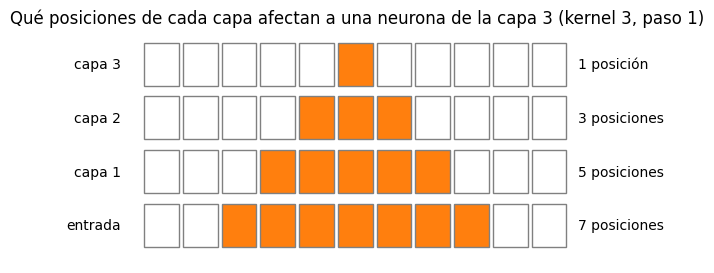

In [7]:
fig, eje = plt.subplots(figsize=(8, 3))
ancho = 11
for fila in range(4):                         # fila 0: la entrada; fila 3: la salida
    usadas = range(5 - (3 - fila), 6 + (3 - fila))  # 1, 3, 5 y 7 posiciones alrededor de la 5
    for posicion in range(ancho):
        color = "tab:orange" if posicion in usadas else "white"
        eje.add_patch(Rectangle((posicion, fila), 0.9, 0.8, facecolor=color, edgecolor="gray"))
    eje.text(-0.6, fila + 0.4, ["entrada", "capa 1", "capa 2", "capa 3"][fila], ha="right", va="center")
    eje.text(ancho + 0.2, fila + 0.4, f"{len(usadas)} posici" + ("ón" if len(usadas) == 1 else "ones"), va="center")
eje.set_xlim(-2.5, ancho + 2.5)
eje.set_ylim(-0.3, 4)
eje.axis("off")
eje.set_title("Qué posiciones de cada capa afectan a una neurona de la capa 3 (kernel 3, paso 1)")
plt.show()

Contamos los parámetros con capas de PyTorch de 64 canales, sin sesgo, y medimos el campo receptivo con la fórmula:

In [8]:
C = 64
configuraciones = {
    "una de 3 × 3":   [nn.Conv2d(C, C, 3, padding=1, bias=False)],
    "dos de 3 × 3":   [nn.Conv2d(C, C, 3, padding=1, bias=False) for _ in range(2)],
    "una de 5 × 5":   [nn.Conv2d(C, C, 5, padding=2, bias=False)],
    "tres de 3 × 3":  [nn.Conv2d(C, C, 3, padding=1, bias=False) for _ in range(3)],
    "una de 7 × 7":   [nn.Conv2d(C, C, 7, padding=3, bias=False)],
}
print(f"{'capas':14s} {'campo receptivo':>16s} {'parámetros':>11s} {'en C²':>6s}")
for nombre, capas in configuraciones.items():
    red = nn.Sequential(*capas)
    n = sum(p.numel() for p in red.parameters())
    r = campo(capas_de(red))
    print(f"{nombre:14s} {r:>12d} × {r:<2d} {n:>11,d} {n // C**2:>6d}".replace(",", "."))

capas           campo receptivo  parámetros  en C²
una de 3 × 3              3 × 3       36.864      9
dos de 3 × 3              5 × 5       73.728     18
una de 5 × 5              5 × 5      102.400     25
tres de 3 × 3             7 × 7      110.592     27
una de 7 × 7              7 × 7      200.704     49


Tres capas de 3 × 3 ven exactamente lo mismo que una de 7 × 7 con 110.592 parámetros en vez de 200.704: $27C^2$ contra $49C^2$, un 45% menos. Con dos capas de 3 × 3 contra una de 5 × 5 pasa lo mismo, $18C^2$ contra $25C^2$. `dos_bloques` y `tres_bloques` siguen esa receta: todas sus convoluciones son de 3 × 3.

## 6. La región en la imagen

Saber el tamaño no basta para saber **qué** píxeles ve una neurona. El artículo llama $u_l$ y $v_l$ a la primera y la última posición de $f_l$ que afectan a una neurona de la salida, con coordenadas que empiezan en 0. Si la neurona está en la posición $u_L = v_L$ de la salida, la región en la capa anterior va de ([Distill, *Computing receptive field region in input image*](https://distill.pub/2019/computing-receptive-fields/)):

$$u_{l-1} = -p_l + u_l \cdot s_l \qquad\qquad v_{l-1} = -p_l + v_l \cdot s_l + k_l - 1$$

La primera posición es la esquina izquierda del primer kernel, que empieza en $-p_l$ porque el relleno queda a la izquierda de la posición 0. Resuelta hasta la entrada, la fórmula de $u_0$ se simplifica con dos cantidades que dependen solo de los pasos y los rellenos:

- el **paso efectivo** $S_0 = \prod_{i=1}^{L} s_i$: la distancia en la imagen entre dos neuronas vecinas de la salida;
- el **relleno efectivo** $P_0 = \sum_{l=1}^{L} p_l \prod_{i=1}^{l-1} s_i$: cuánto relleno se acumula, visto desde la imagen.

Con ellas:

$$u_0 = -P_0 + u_L \cdot S_0 \qquad\qquad v_0 = u_0 + r_0 - 1 \qquad\qquad c_0 = -P_0 + u_L \cdot S_0 + \frac{r_0 - 1}{2}$$

donde $c_0$ es el centro de la región. El artículo da un ejemplo con dos capas, la primera con $k_1 = 3$, $p_1 = 1$, $s_1 = 3$ y la segunda con $k_2 = 2$, $p_2 = 0$, $s_2 = 1$: la primera neurona de la salida usa las posiciones $u_0 = -1$ a $v_0 = 4$ de la entrada. Lo reproducimos:

In [9]:
def paso_efectivo(capas):
    return math.prod(capa.s for capa in capas)


def relleno_efectivo(capas):
    P, paso = 0, 1
    for capa in capas:
        P += capa.p * paso
        paso *= capa.s
    return P


def region(capas, u):
    """Primera y última posición de la entrada (en una dimensión) que afectan a la neurona u de la salida."""
    inicio = -relleno_efectivo(capas) + u * paso_efectivo(capas)
    return inicio, inicio + campo(capas) - 1


def centro(capas, u):
    return -relleno_efectivo(capas) + u * paso_efectivo(capas) + (campo(capas) - 1) / 2


ejemplo = [Capa("conv", 3, 3, 1), Capa("conv", 2, 1, 0)]
print("ejemplo del artículo, primera neurona: (u0, v0) =", region(ejemplo, 0))

ejemplo del artículo, primera neurona: (u0, v0) = (-1, 4)


Sale $(-1, 4)$, como en el artículo. La posición $-1$ está en el relleno: esa neurona mira un píxel que no existe.

La función `region` calcula $v_0$ con $v_0 = u_0 + r_0 - 1$. El artículo también da una fórmula para $v_0$ que usa los kernels directamente, $v_0 = v_L \prod s_i - \sum (1 + p_l - k_l) \prod_{i<l} s_i$, y deja como ejercicio probar que las dos coinciden. Además da recurrencias para el paso y el relleno efectivos, $S_{l-1} = s_l \cdot S_l$ y $P_{l-1} = s_l \cdot P_l + p_l$. Comprobamos todo con las mil redes al azar y varias posiciones de salida:

In [10]:
def ultima_segun_kernels(capas, u):
    v, paso = u * paso_efectivo(capas), 1
    for capa in capas:
        v -= (1 + capa.p - capa.k) * paso
        paso *= capa.s
    return v


def paso_y_relleno_recursivos(capas):
    S, P = 1, 0                              # en la salida: S_L = 1, P_L = 0
    for capa in reversed(capas):
        S, P = capa.s * S, capa.s * P + capa.p
    return S, P


iguales_v = sum(region(c, u)[1] == ultima_segun_kernels(c, u) for c in redes for u in range(5))
iguales_SP = sum(paso_y_relleno_recursivos(c) == (paso_efectivo(c), relleno_efectivo(c)) for c in redes)
print("v0 por las dos fórmulas coincide en", iguales_v, "de", 5 * len(redes), "casos")
print("S0 y P0 por recurrencia coinciden en", iguales_SP, "de", len(redes), "redes")

v0 por las dos fórmulas coincide en 5000 de 5000 casos
S0 y P0 por recurrencia coinciden en 1000 de 1000 redes


Todo coincide. Ahora las regiones de `dos_bloques`, en una dimensión (en dos dimensiones es lo mismo en filas y en columnas). Su salida es un mapa de 7 × 7:

In [11]:
capas_dos = capas_de(dos_bloques)
print(f"r0 = {campo(capas_dos)}   S0 = {paso_efectivo(capas_dos)}   P0 = {relleno_efectivo(capas_dos)}\n")
for u in range(7):
    inicio, fin = region(capas_dos, u)
    print(f"neurona {u}: píxeles {inicio:3d} a {fin:2d}   centro {centro(capas_dos, u):5.1f}"
          f"   dentro de la imagen: {max(inicio, 0):2d} a {min(fin, 27):2d}")

r0 = 10   S0 = 4   P0 = 3

neurona 0: píxeles  -3 a  6   centro   1.5   dentro de la imagen:  0 a  6
neurona 1: píxeles   1 a 10   centro   5.5   dentro de la imagen:  1 a 10
neurona 2: píxeles   5 a 14   centro   9.5   dentro de la imagen:  5 a 14
neurona 3: píxeles   9 a 18   centro  13.5   dentro de la imagen:  9 a 18
neurona 4: píxeles  13 a 22   centro  17.5   dentro de la imagen: 13 a 22
neurona 5: píxeles  17 a 26   centro  21.5   dentro de la imagen: 17 a 26
neurona 6: píxeles  21 a 30   centro  25.5   dentro de la imagen: 21 a 27


Las regiones tienen 10 píxeles, empiezan cada 4 ($S_0 = 4$) y se superponen en 6. La primera empieza en $-3$ ($P_0 = 3$): tres de sus píxeles son relleno, así que en la imagen ve solo 7. La última va de 21 a 30, y como el último píxel de la imagen es el 27, también ve solo 7. Los centros van de 1.5 a 25.5, a 4 píxeles uno de otro, y el centro de la imagen de 28 píxeles, 13.5, coincide con el centro de la neurona 3.

## 7. Comprobarlo con gradientes

Las fórmulas dicen qué región **puede** influir en una neurona. Para comprobarlas sin que nada esconda un píxel, armamos una versión lineal de cada red con la misma geometría: cada convolución pasa a tener un canal y todos sus pesos iguales a 1, cada pooling pasa a ser un promedio, y las ReLU se quitan. Con pesos positivos ningún camino se cancela, así que el gradiente es distinto de 0 exactamente en los píxeles que influyen. Como $k$, $s$ y $p$ no cambian, el campo receptivo es el mismo.

Comparamos, para **todas** las neuronas de la salida, la máscara del gradiente con la región que calculan las fórmulas, recortada a la imagen:

In [12]:
def version_lineal(modelo):
    capas = []
    for m in modelo.modules():
        if isinstance(m, nn.Conv2d):
            c = nn.Conv2d(1, 1, m.kernel_size, m.stride, m.padding, m.dilation, bias=False)
            nn.init.ones_(c.weight)
            capas.append(c)
        elif isinstance(m, (nn.MaxPool2d, nn.AvgPool2d)):
            capas.append(nn.AvgPool2d(m.kernel_size, m.stride, m.padding))
    return nn.Sequential(*capas)


def gradiente_de_una_neurona(red, tamano, i, j):
    x = torch.zeros(1, 1, tamano, tamano, requires_grad=True)
    red(x)[0, 0, i, j].backward()
    return x.grad[0, 0]


def region_esperada(capas, tamano, i, j):
    mascara = torch.zeros(tamano, tamano, dtype=torch.bool)
    fila_inicio, fila_fin = region(capas, i)
    col_inicio, col_fin = region(capas, j)
    mascara[max(fila_inicio, 0):min(fila_fin, tamano - 1) + 1, max(col_inicio, 0):min(col_fin, tamano - 1) + 1] = True
    return mascara


for nombre, red, tamano in [("dos_bloques", dos_bloques, 28), ("tres_bloques", tres_bloques, 32)]:
    lineal, capas = version_lineal(red), capas_de(red)
    lado = lineal(torch.zeros(1, 1, tamano, tamano)).shape[-1]
    aciertos = sum(torch.equal(gradiente_de_una_neurona(lineal, tamano, i, j) != 0, region_esperada(capas, tamano, i, j))
                   for i in range(lado) for j in range(lado))
    print(f"{nombre}: la región coincide píxel a píxel en {aciertos} de {lado * lado} neuronas de la salida")

dos_bloques: la región coincide píxel a píxel en 49 de 49 neuronas de la salida


tres_bloques: la región coincide píxel a píxel en 16 de 16 neuronas de la salida


Las fórmulas aciertan en las 49 neuronas de `dos_bloques` y en las 16 de `tres_bloques`, incluidas las del borde, donde parte de la región cae en el relleno. La figura muestra tres neuronas de `dos_bloques`. El rectángulo naranjo es la región que calcula la fórmula, incluida la parte que cae fuera de la imagen; el color es el valor del gradiente:

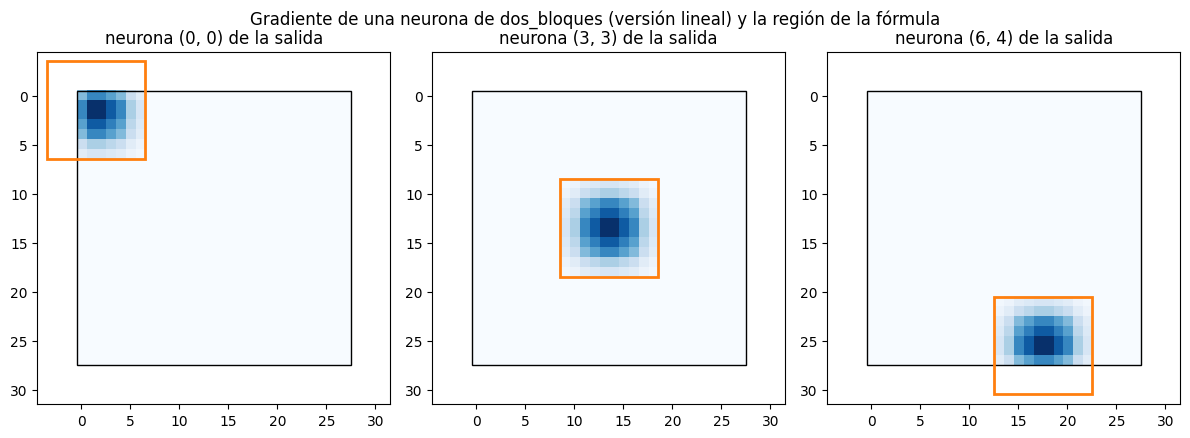

In [13]:
lineal = version_lineal(dos_bloques)
fig, ejes = plt.subplots(1, 3, figsize=(12, 4.2))
for eje, (i, j) in zip(ejes, [(0, 0), (3, 3), (6, 4)]):
    g = gradiente_de_una_neurona(lineal, 28, i, j)
    eje.imshow(g, cmap="Blues", extent=(-0.5, 27.5, 27.5, -0.5))
    eje.add_patch(Rectangle((-0.5, -0.5), 28, 28, fill=False, edgecolor="black", linewidth=1))
    fila_inicio, fila_fin = region(capas_dos, i)
    col_inicio, col_fin = region(capas_dos, j)
    eje.add_patch(Rectangle((col_inicio - 0.5, fila_inicio - 0.5), col_fin - col_inicio + 1, fila_fin - fila_inicio + 1,
                            fill=False, edgecolor="tab:orange", linewidth=2))
    eje.set_xlim(-4.5, 31.5)
    eje.set_ylim(31.5, -4.5)
    eje.set_title(f"neurona ({i}, {j}) de la salida")
plt.suptitle("Gradiente de una neurona de dos_bloques (versión lineal) y la región de la fórmula")
plt.tight_layout()
plt.show()

En la esquina, la región de la fórmula sale 3 píxeles por arriba y por la izquierda de la imagen: esa parte es relleno, y el gradiente, que solo existe sobre píxeles reales, cubre lo que queda adentro. En el centro, la región cae entera en la imagen. El gradiente tampoco es parejo dentro del rectángulo: es más intenso hacia el centro. Volveremos a eso en la sección 11.

## 8. Con ReLU y max pooling

La red real tiene ReLU y max pooling, y esas dos capas eligen: el max pooling deja pasar el gradiente solo al máximo de cada ventana, y la ReLU lo corta donde su entrada fue negativa. Para una imagen concreta, entonces, una neurona usa solo una parte de su región. Lo medimos con `dos_bloques` y sus pesos al azar, para la neurona del centro de la salida, (3, 3), en cada uno de sus 64 canales:

In [14]:
def es_cuadrado_lleno(mascara, lado):
    filas, columnas = mascara.any(1).nonzero().flatten(), mascara.any(0).nonzero().flatten()
    alto, ancho = filas.max() - filas.min() + 1, columnas.max() - columnas.min() + 1
    return bool(alto == ancho == lado and mascara.sum() == lado * lado)


esperada = region_esperada(capas_dos, 28, 3, 3)
torch.manual_seed(1)
x = torch.randn(1, 1, 28, 28, requires_grad=True)
y = dos_bloques(x)

tamanos, fuera_de_la_region, cuadrados = [], 0, 0
for canal in range(64):
    g, = torch.autograd.grad(y[0, canal, 3, 3], x, retain_graph=True)
    usados = g[0, 0] != 0
    tamanos.append(usados.sum().item())
    fuera_de_la_region += (usados & ~esperada).sum().item()
    if usados.any():
        cuadrados += es_cuadrado_lleno(usados, 8)

vivos = [t for t in tamanos if t > 0]
print("píxeles de la región:", esperada.sum().item())
print("píxeles con gradiente fuera de la región, en los 64 canales:", fuera_de_la_region)
print("canales sin ningún píxel con gradiente:", tamanos.count(0))
print("píxeles usados por los demás canales:", sorted(set(vivos)))
print("canales cuyos píxeles forman un cuadrado lleno de 8 × 8:", cuadrados, "de", len(vivos))

píxeles de la región: 100
píxeles con gradiente fuera de la región, en los 64 canales: 0
canales sin ningún píxel con gradiente: 15
píxeles usados por los demás canales: [64]
canales cuyos píxeles forman un cuadrado lleno de 8 × 8: 49 de 49


Ningún canal usa un píxel fuera de la región: la fórmula es un límite que se cumple siempre. Pero ningún canal usa la región completa con esta imagen, y 15 canales no usan nada: para esta entrada, su ReLU quedó apagada en la posición (3, 3), y el gradiente es 0 en todas partes.

Los otros 49 canales usan exactamente 64 píxeles, y en todos forman un cuadrado lleno de 8 × 8. Ese es el campo receptivo de la segunda convolución (la tabla de la sección 9 lo confirma). El último max pooling elige una de las cuatro posiciones de su ventana de 2 × 2, y cada una de esas posiciones ve 8 × 8 píxeles. El primer max pooling también elige, pero lo hace por separado en cada uno de los 32 canales de la primera convolución, y entre todos cubren el cuadrado completo.

Con otra imagen, el max pooling elige otros máximos y la ReLU apaga otras neuronas. Si juntamos los píxeles usados por un mismo canal con muchas imágenes al azar, la unión debería llenar la región:

In [15]:
canal = max(range(64), key=lambda c: tamanos[c])        # el canal que más píxeles usó con la primera imagen
torch.manual_seed(2)
union = torch.zeros(28, 28, dtype=torch.bool)
for n in range(1, 51):
    x = torch.randn(1, 1, 28, 28, requires_grad=True)
    dos_bloques(x)[0, canal, 3, 3].backward()
    union |= x.grad[0, 0] != 0
    if n in (1, 2, 5, 10, 50):
        print(f"{n:2d} imágenes: la unión cubre {union.sum().item():3d} de {esperada.sum().item()} píxeles, "
              f"fuera de la región: {(union & ~esperada).sum().item()}")

 1 imágenes: la unión cubre  64 de 100 píxeles, fuera de la región: 0
 2 imágenes: la unión cubre  64 de 100 píxeles, fuera de la región: 0
 5 imágenes: la unión cubre  96 de 100 píxeles, fuera de la región: 0
10 imágenes: la unión cubre  96 de 100 píxeles, fuera de la región: 0


50 imágenes: la unión cubre 100 de 100 píxeles, fuera de la región: 0


La unión crece de a cuadrados de 8 × 8. Con una y dos imágenes el último max pooling eligió la misma posición, y la unión sigue en 64. Con cinco ya eligió tres de sus cuatro posiciones: tres cuadrados de 8 × 8 corridos en 2 píxeles cubren 96 de los 100 píxeles, todos menos una esquina de 2 × 2. Con 50 imágenes la unión llena la región, y nunca sale de ella. Así se lee el campo receptivo de una red real: es la región que **puede** influir en una neurona. Cuáles píxeles influyen de verdad depende de la imagen.

## 9. Las redes del módulo y la tabla del artículo

Una tabla capa por capa dice qué ve cada neurona a medida que la imagen avanza por la red. Para cada capa se aplica la fórmula a la red cortada en esa capa: el tamaño del mapa de salida, el campo receptivo, el paso efectivo y qué fracción del área de la imagen cubre el campo receptivo.

In [16]:
def tabla(capas, lado):
    print(f"{'capa':10s} {'k':>2s} {'s':>2s} {'p':>2s}   {'mapa':>7s}   {'campo':>7s}   {'paso':>4s}   {'área de la imagen':>17s}")
    lado_imagen = lado
    for l, capa in enumerate(capas, start=1):
        lado = (lado + 2 * capa.p - capa.k) // capa.s + 1
        r = campo(capas[:l])
        area = min(r, lado_imagen) ** 2 / lado_imagen ** 2
        print(f"{capa.nombre:10s} {capa.k:2d} {capa.s:2d} {capa.p:2d}   {lado:3d} × {lado:<2d}  {r:3d} × {r:<2d}"
              f"  {paso_efectivo(capas[:l]):4d}   {area:17.0%}")


print("dos_bloques, imagen de 28 × 28\n")
tabla(capas_dos, 28)
print("\ntres_bloques, imagen de 32 × 32\n")
tabla(capas_de(tres_bloques), 32)

dos_bloques, imagen de 28 × 28

capa        k  s  p      mapa     campo   paso   área de la imagen
Conv2d      3  1  1    28 × 28    3 × 3      1                  1%
MaxPool2d   2  2  0    14 × 14    4 × 4      2                  2%
Conv2d      3  1  1    14 × 14    8 × 8      2                  8%
MaxPool2d   2  2  0     7 × 7    10 × 10     4                 13%

tres_bloques, imagen de 32 × 32

capa        k  s  p      mapa     campo   paso   área de la imagen
Conv2d      3  1  1    32 × 32    3 × 3      1                  1%
MaxPool2d   2  2  0    16 × 16    4 × 4      2                  2%
Conv2d      3  1  1    16 × 16    8 × 8      2                  6%
MaxPool2d   2  2  0     8 × 8    10 × 10     4                 10%
Conv2d      3  1  1     8 × 8    18 × 18     4                 32%
MaxPool2d   2  2  0     4 × 4    22 × 22     8                 47%


- En `dos_bloques`, la primera convolución ve 3 × 3 píxeles y la salida, 10 × 10: el 13% del área de la imagen. En `tres_bloques`, la salida ve 22 × 22 de 32 × 32, el 47%.
- El pooling cuenta poco por sí mismo (su kernel de 2 agrega 1 posición), pero duplica el paso efectivo, y con eso duplica lo que aporta cada convolución que viene después: la primera convolución agrega 2 píxeles, la segunda 4 y la tercera 8.
- Ninguna neurona convolucional de estas redes ve la imagen completa. Las ve la capa lineal del final: después de `Flatten`, cada salida combina todas las posiciones del mapa, y por lo tanto todos los píxeles. Las convoluciones encuentran rasgos locales y la capa lineal los junta.

El artículo publica una tabla con el campo receptivo ($r$), el paso efectivo ($S$) y el relleno efectivo ($P$) de varias redes conocidas, calculados con su librería sobre los modelos de TF-Slim ([Distill, *Discussion: receptive fields of modern networks*](https://distill.pub/2019/computing-receptive-fields/)). Dos de sus filas: `alexnet_v2`, con $r = 195$, $S = 32$, $P = 64$, y `vgg_16`, con $r = 212$, $S = 32$, $P = 90$. Calculamos lo mismo sobre la parte convolucional (`features`) de los modelos de `torchvision`, creados sin pesos:

In [17]:
for nombre, constructor in [("vgg16", torchvision.models.vgg16), ("alexnet", torchvision.models.alexnet)]:
    capas = capas_de(constructor(weights=None).features)
    print(f"{nombre:8s} {len(capas):2d} capas   r = {campo(capas)}   S = {paso_efectivo(capas)}   P = {relleno_efectivo(capas)}")

capas_alexnet = capas_de(torchvision.models.alexnet(weights=None).features)
print("\nprimera capa de alexnet en torchvision:", capas_alexnet[0])
capas_alexnet[0].p = 0
print("con esa capa sin relleno: P =", relleno_efectivo(capas_alexnet))

vgg16    18 capas   r = 212   S = 32   P = 90


alexnet   8 capas   r = 195   S = 32   P = 66



primera capa de alexnet en torchvision: Capa(nombre='Conv2d', k=11, s=4, p=2)
con esa capa sin relleno: P = 64


VGG-16 coincide en los tres números: 212, 32 y 90. AlexNet coincide en $r$ y $S$, pero da $P = 66$ en vez de 64. La diferencia está en la primera convolución: la de `torchvision` tiene relleno 2, y sin ese relleno sale exactamente 64. Eso sugiere que en la versión de TF-Slim que usa el artículo esa capa no tiene relleno; no lo comprobamos en el código de TF-Slim. El relleno no cambia el campo receptivo, 195 en los dos casos, pero sí dónde queda.

Una neurona de la salida de VGG-16 ve 212 × 212 píxeles, casi toda una imagen de 224 × 224.

## 10. Convoluciones dilatadas

Una convolución dilatada aplica su kernel con huecos: con dilatación 2, un kernel de 3 mira las posiciones 0, 2 y 4 en vez de 0, 1 y 2. Los apuntes de CS231n la presentan como una forma de "juntar información espacial de las entradas de forma mucho más agresiva con menos capas" ([CS231n, *Convolutional Layer*, *Dilated convolutions*](https://cs231n.github.io/convolutional-networks/#conv)). Para el campo receptivo, el artículo indica que basta reemplazar el tamaño del kernel $k$ por $\alpha(k - 1) + 1$ en cada capa con dilatación $\alpha$ ([Distill, apéndice *Other network operations*](https://distill.pub/2019/computing-receptive-fields/)). Es lo que hace la línea con `d` en `capas_de`.

Comparamos tres capas de 3 × 3 normales con tres capas de 3 × 3 con dilataciones 1, 2 y 4 (el relleno igual a la dilatación mantiene el tamaño del mapa):

In [18]:
normal = nn.Sequential(
    nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(),
    nn.Conv2d(8, 8, 3, padding=1), nn.ReLU(),
    nn.Conv2d(8, 8, 3, padding=1),
)
dilatada = nn.Sequential(
    nn.Conv2d(1, 8, 3, padding=1, dilation=1), nn.ReLU(),
    nn.Conv2d(8, 8, 3, padding=2, dilation=2), nn.ReLU(),
    nn.Conv2d(8, 8, 3, padding=4, dilation=4),
)
for nombre, red in [("normal", normal), ("dilatada", dilatada)]:
    capas = capas_de(red)
    lineal = version_lineal(red)
    aciertos = sum(torch.equal(gradiente_de_una_neurona(lineal, 32, i, j) != 0, region_esperada(capas, 32, i, j))
                   for i in range(32) for j in range(32))
    print(f"{nombre:9s} parámetros {sum(p.numel() for p in red.parameters()):5d}   campo receptivo {campo(capas):2d}"
          f"   la región coincide en {aciertos} de 1024 neuronas")

normal    parámetros  1248   campo receptivo  7   la región coincide en 1024 de 1024 neuronas


dilatada  parámetros  1248   campo receptivo 15   la región coincide en 1024 de 1024 neuronas


Con los mismos parámetros, la versión dilatada ve 15 × 15 píxeles en vez de 7 × 7, y la fórmula vuelve a acertar en todas las neuronas.

Hay un detalle. El campo receptivo es la región que abarca la neurona, desde la primera hasta la última posición, pero eso no garantiza que use **todos** los píxeles de en medio. El artículo lo advierte: la región puede tener "agujeros" ([Distill, *Computing receptive field size*](https://distill.pub/2019/computing-receptive-fields/)). Una sola capa dilatada es el caso más claro:

In [19]:
una_dilatada = nn.Conv2d(1, 1, 3, dilation=2, bias=False)
nn.init.ones_(una_dilatada.weight)
print("una capa de 3 × 3 con dilatación 2 (campo receptivo", campo(capas_de(una_dilatada)), "):")
dibujar(pixeles_que_influyen(una_dilatada, 9)[2:7, 2:7])
print("\nla pila con dilataciones 1, 2 y 4, alrededor de la neurona central:")
dibujar(gradiente_de_una_neurona(version_lineal(dilatada), 32, 16, 16)[9:24, 9:24] != 0)

una capa de 3 × 3 con dilatación 2 (campo receptivo 5 ):
■ · ■ · ■
· · · · ·
■ · ■ · ■
· · · · ·
■ · ■ · ■

la pila con dilataciones 1, 2 y 4, alrededor de la neurona central:
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■
■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■ ■


La capa sola abarca 5 × 5 pero usa 9 píxeles: los demás son agujeros. En la pila con dilataciones 1, 2 y 4 no quedan agujeros: la primera capa, sin dilatación, rellena los espacios que dejan las siguientes. Por eso la comprobación anterior dio 1024 de 1024: con agujeros, la máscara del gradiente no habría sido un cuadrado lleno.

## 11. El campo receptivo efectivo

En la figura de la sección 7, el gradiente era más intenso en el centro de la región. El artículo lo explica al cerrar su discusión: una neurona no recibe el mismo efecto de todos los píxeles de su campo receptivo, porque los del centro tienen más "caminos" para influir en ella y por eso pesan más. La importancia relativa de cada píxel define el **campo receptivo efectivo**, y el artículo cita el trabajo que lo estudió, que observó experimentalmente "una forma gaussiana, con el máximo en el centro del campo receptivo" ([Distill, *Discussion: receptive fields of modern networks*](https://distill.pub/2019/computing-receptive-fields/)).

Ese trabajo es [Luo, Li, Urtasun y Zemel (2016), *Understanding the Effective Receptive Field in Deep Convolutional Neural Networks*](https://arxiv.org/abs/1701.04128). Mide la importancia de cada píxel con la derivada $\partial y_{0,0} / \partial x_{i,j}$ de la neurona central de la salida respecto de cada píxel, y la calcula con retropropagación poniendo el gradiente de la salida en 1 en esa neurona y en 0 en las demás ([sección 2](https://arxiv.org/abs/1701.04128)). Es exactamente lo que venimos haciendo.

Para el caso más simple, $n$ capas convolucionales con todos los pesos iguales y sin no linealidades, el artículo prueba que el efecto se reparte como una gaussiana y que su desviación estándar, que toma como el radio del campo receptivo efectivo, crece como $\sqrt{n}$, mientras el campo receptivo teórico crece como $n$. Para kernels de tamaño $k$ con pesos $1/k$, la desviación en cada eje es $\sqrt{n(k^2 - 1)/12}$ ([sección 2.3, ecuación 11](https://arxiv.org/abs/1701.04128)). Lo comprobamos con pilas de 5 a 40 capas de 3 × 3 sobre una entrada de 101 × 101:

In [20]:
def pila(n, aleatoria=False, relu=False, k=3):
    capas = []
    for _ in range(n):
        c = nn.Conv2d(1, 1, k, padding=k // 2, bias=False)
        if aleatoria:
            nn.init.normal_(c.weight)
        else:
            nn.init.constant_(c.weight, 1 / k**2)
        capas.append(c)
        if relu:
            capas.append(nn.ReLU())
    return nn.Sequential(*capas)


def importancia(red, lado, repeticiones=1):
    """Promedio de |dy/dx| de la neurona central, normalizado para que sume 1."""
    total = torch.zeros(lado, lado)
    for _ in range(repeticiones):
        x = torch.randn(1, 1, lado, lado, requires_grad=True)
        red(x)[0, 0, lado // 2, lado // 2].backward()
        total += x.grad[0, 0].abs()
    if total.sum() == 0:
        return None                 # ningún camino llega a la neurona: el gradiente es 0 en todas partes
    return total / total.sum()


def desviacion_por_eje(mapa):
    """Desviación estándar de la importancia a lo largo de las filas, alrededor de su propio centro."""
    perfil = mapa.sum(1)                                   # importancia total de cada fila
    posiciones = torch.arange(len(perfil), dtype=torch.float)
    media = (perfil * posiciones).sum()
    return (perfil * (posiciones - media) ** 2).sum().sqrt().item()


def tamano_efectivo(mapa):
    """La medida de Luo y otros: raíz del número de píxeles con más de 1 - 95.45% del valor del centro."""
    centro_valor = mapa[mapa.shape[0] // 2, mapa.shape[1] // 2]
    return math.sqrt((mapa > (1 - 0.9545) * centro_valor).sum().item())


lado = 101
filas = []
print(f"{'capas':>5s} {'campo teórico':>14s} {'desviación medida':>18s} {'fórmula':>8s} {'tamaño efectivo':>16s} {'efectivo / teórico':>19s}")
for n in [5, 10, 20, 40]:
    mapa = importancia(pila(n), lado)
    teorico = campo(capas_de(pila(n)))
    efectivo = tamano_efectivo(mapa)
    filas.append((n, teorico, efectivo))
    print(f"{n:5d} {teorico:>14d} {desviacion_por_eje(mapa):>18.3f} {math.sqrt(n * (3**2 - 1) / 12):>8.3f}"
          f" {efectivo:>16.2f} {efectivo / teorico:>19.3f}")

capas  campo teórico  desviación medida  fórmula  tamaño efectivo  efectivo / teórico
    5             11              1.826    1.826             8.31               0.755
   10             21              2.582    2.582            11.70               0.557
   20             41              3.651    3.651            16.16               0.394


   40             81              5.164    5.164            22.74               0.281


La desviación medida coincide con la fórmula del artículo en los tres decimales para las cuatro profundidades. Al pasar de 5 a 40 capas (8 veces más), el campo teórico crece de 11 a 81 píxeles, casi 8 veces, mientras la desviación crece de 1.83 a 5.16, unas $\sqrt{8} \approx 2.8$ veces.

La columna "tamaño efectivo" usa la medida de la [sección 3.1 del artículo](https://arxiv.org/abs/1701.04128): cuenta los píxeles cuyo valor supera $1 - 95.45\%$ del valor del centro (dos desviaciones estándar) y toma la raíz. En escala logarítmica, el artículo encontró pendientes de 0.56 para el tamaño efectivo y de −0.43 para la razón entre el efectivo y el teórico, es decir, crecimiento como $\sqrt{n}$ y achicamiento relativo como $1/\sqrt{n}$. Medimos las nuestras:

pendiente del tamaño efectivo   : 0.48   (artículo: 0.56)
pendiente de efectivo / teórico : -0.48   (artículo: -0.43)


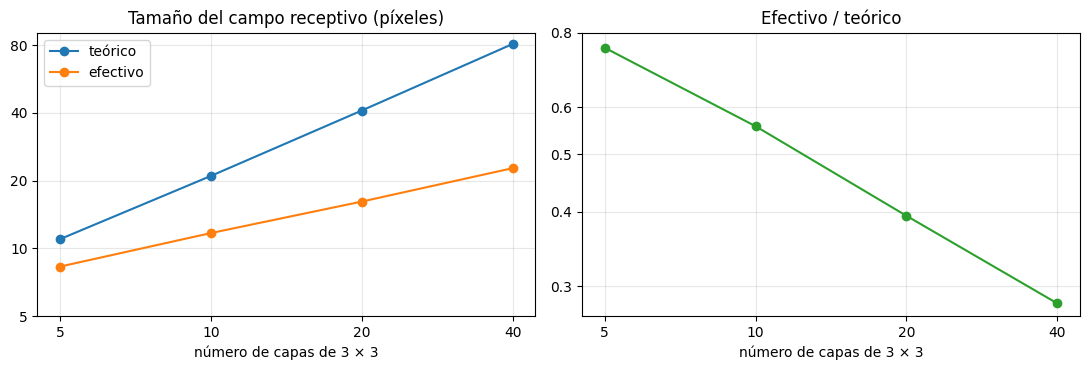

In [21]:
log_n = torch.log(torch.tensor([f[0] for f in filas], dtype=torch.float))
log_efectivo = torch.log(torch.tensor([f[2] for f in filas]))
log_razon = torch.log(torch.tensor([f[2] / f[1] for f in filas]))


def pendiente(x, y):
    x_c = x - x.mean()
    return ((x_c * (y - y.mean())).sum() / (x_c**2).sum()).item()


print(f"pendiente del tamaño efectivo   : {pendiente(log_n, log_efectivo):.2f}   (artículo: 0.56)")
print(f"pendiente de efectivo / teórico : {pendiente(log_n, log_razon):.2f}   (artículo: -0.43)")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].loglog([f[0] for f in filas], [f[1] for f in filas], "o-", label="teórico")
ejes[0].loglog([f[0] for f in filas], [f[2] for f in filas], "o-", label="efectivo")
ejes[0].set_title("Tamaño del campo receptivo (píxeles)")
ejes[1].loglog([f[0] for f in filas], [f[2] / f[1] for f in filas], "o-", color="tab:green")
ejes[1].set_title("Efectivo / teórico")
ejes[0].set_yticks([5, 10, 20, 40, 80], labels=["5", "10", "20", "40", "80"])
ejes[1].set_yticks([0.3, 0.4, 0.5, 0.6, 0.8], labels=["0.3", "0.4", "0.5", "0.6", "0.8"])
for eje in ejes:
    eje.minorticks_off()
    eje.set_xlabel("número de capas de 3 × 3")
    eje.set_xticks([5, 10, 20, 40], labels=["5", "10", "20", "40"])
    eje.grid(alpha=0.3)
ejes[0].legend()
plt.tight_layout()
plt.show()

Nuestras pendientes no son las del artículo, que trabajó con sus propias redes y promedió 20 ejecuciones, pero muestran lo mismo: el tamaño efectivo crece más o menos como $\sqrt{n}$ y la fracción del campo teórico que ocupa cae más o menos como $1/\sqrt{n}$. Con 40 capas, el campo receptivo efectivo ocupa menos de un tercio del lado del teórico.

¿Cuánto del efecto se concentra en el centro? Con 10 capas, el campo teórico tiene 21 × 21 = 441 píxeles. Ordenamos los píxeles de mayor a menor importancia y contamos cuántos hacen falta para juntar el 50%, el 90% y el 99% del total:

In [22]:
mapa = importancia(pila(10), lado)
acumulado = mapa.flatten().sort(descending=True).values.cumsum(0)
for fraccion in [0.5, 0.9, 0.99]:
    necesarios = (acumulado < fraccion).sum().item() + 1
    print(f"el {fraccion:.0%} de la importancia está en {necesarios:3d} de 441 píxeles ({necesarios / 441:.0%} del campo teórico)")

el 50% de la importancia está en  30 de 441 píxeles (7% del campo teórico)
el 90% de la importancia está en  96 de 441 píxeles (22% del campo teórico)
el 99% de la importancia está en 183 de 441 píxeles (41% del campo teórico)


La mitad de la importancia está en el 7% central del campo receptivo, y el 90% en poco más de un quinto. Los píxeles de las orillas existen en el campo receptivo, pero casi no pesan.

Los pesos iguales son el caso de la teoría. El artículo también mira pesos al azar y pesos al azar con ReLU ([su sección 3.1 y su figura 1](https://arxiv.org/abs/1701.04128)): con pesos al azar sin no linealidad la forma sigue siendo gaussiana, y con ReLU es "casi gaussiana". Con ReLU hay además un problema práctico que el artículo menciona en la [misma sección 3.1](https://arxiv.org/abs/1701.04128): la ReLU da exactamente 0 para la mitad de sus entradas, y es fácil que la neurona central de la salida quede en 0; entonces ningún camino llega a ella y el gradiente es 0 en todas partes. Repetimos la figura con 10 capas, promediando 20 redes al azar con una entrada al azar cada una, y contamos cuántas redes quedan con el gradiente en 0:

pesos al azar  : 0 de 20 redes con el gradiente en 0 en todas partes


al azar + ReLU : 10 de 20 redes con el gradiente en 0 en todas partes


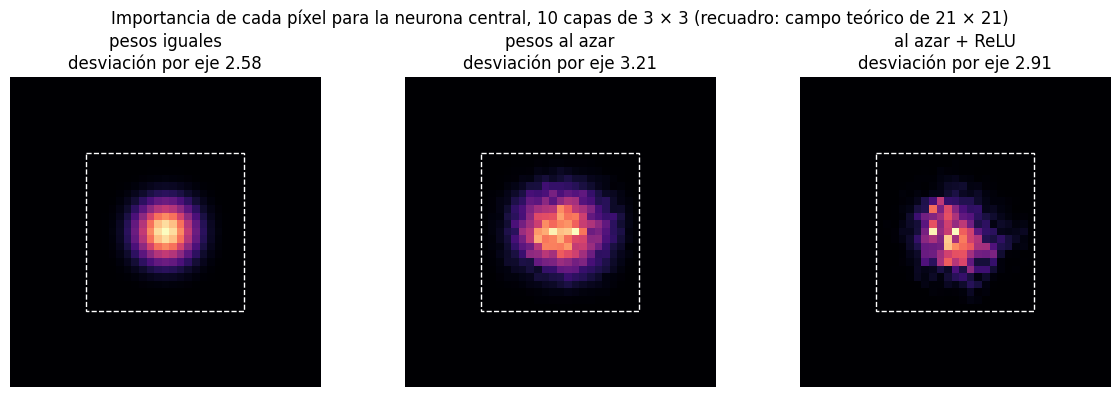

In [23]:
def promedio_de_redes(crear, lado, repeticiones=20):
    mapas = [importancia(crear(), lado) for _ in range(repeticiones)]
    validos = [m for m in mapas if m is not None]
    return sum(validos) / len(validos), repeticiones - len(validos)


torch.manual_seed(0)
casos = {"pesos iguales": importancia(pila(10), 41)}
for nombre, relu in [("pesos al azar", False), ("al azar + ReLU", True)]:
    casos[nombre], en_cero = promedio_de_redes(lambda: pila(10, aleatoria=True, relu=relu), 41)
    print(f"{nombre:15s}: {en_cero} de 20 redes con el gradiente en 0 en todas partes")

fig, ejes = plt.subplots(1, 3, figsize=(12, 4))
for eje, (nombre, mapa) in zip(ejes, casos.items()):
    eje.imshow(mapa, cmap="magma")
    eje.add_patch(Rectangle((9.5, 9.5), 21, 21, fill=False, edgecolor="white", linestyle="--"))
    eje.set_title(f"{nombre}\ndesviación por eje {desviacion_por_eje(mapa):.2f}")
    eje.axis("off")
plt.suptitle("Importancia de cada píxel para la neurona central, 10 capas de 3 × 3 (recuadro: campo teórico de 21 × 21)")
plt.tight_layout()
plt.show()

Sin ReLU, ninguna red quedó con el gradiente en 0. Con ReLU, la mitad sí: en 10 de las 20 redes la neurona central dio exactamente 0 y ningún píxel le llegó, el problema que describe el artículo. El promedio de ese caso usa solo las otras 10 redes.

En los tres casos la importancia se concentra en el centro del recuadro, que marca el campo teórico, y se apaga hacia las orillas. Con pesos iguales la mancha es una gaussiana perfecta. Con pesos al azar, promediada sobre 20 redes, la forma se parece, algo más ancha. Con ReLU, la mancha queda más irregular: la ReLU depende de la entrada y corta caminos, y con solo 10 redes en el promedio se nota más el ruido.

## 12. ¿Cambia al entrenar?

Luo y otros observaron que las inicializaciones al azar habituales hacen que algunas redes profundas empiecen con un campo receptivo efectivo chico, "que después crece durante el entrenamiento" ([sección 1](https://arxiv.org/abs/1701.04128)). En su [sección 3.2](https://arxiv.org/abs/1701.04128) entrenan una ResNet de 17 bloques residuales en CIFAR-10, sin pooling, y el campo receptivo efectivo de las neuronas de la última capa termina "significativamente más grande" que al comienzo.

Probamos lo mismo en chico con Fashion-MNIST: una red con cuatro convoluciones de 3 × 3 y dos max pooling, cuya salida convolucional es un mapa de 7 × 7 con un campo receptivo de 16 × 16 píxeles, seguida de una capa lineal. Medimos la importancia de cada píxel para la neurona central del mapa, (3, 3), promediada sobre 256 imágenes de prueba y los 32 canales, antes de entrenar y después de dos épocas con 12.000 imágenes.

In [24]:
entrenamiento = datasets.FashionMNIST(root=RAIZ, train=True, download=True)
prueba = datasets.FashionMNIST(root=RAIZ, train=False, download=True)
media = (entrenamiento.data.float() / 255).mean().item()
desviacion = (entrenamiento.data.float() / 255).std().item()


def preparar(datos):
    return ((datos.data.float() / 255 - media) / desviacion).unsqueeze(1), datos.targets


X_entrenamiento, y_entrenamiento = preparar(entrenamiento)
X_prueba, y_prueba = preparar(prueba)
X_entrenamiento, y_entrenamiento = X_entrenamiento[:12_000], y_entrenamiento[:12_000]

torch.manual_seed(0)
convolucional = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
)
modelo = nn.Sequential(convolucional, nn.Flatten(), nn.Linear(32 * 7 * 7, 10))
capas_red = capas_de(convolucional)
print(f"media {media:.4f}   desviación {desviacion:.4f}")
print("campo receptivo de la parte convolucional:", campo(capas_red), "  región de la neurona (3, 3):", region(capas_red, 3))


def importancia_en_imagenes(convolucional, imagenes):
    x = imagenes.clone().requires_grad_(True)
    salida = convolucional(x)
    total = torch.zeros(28, 28)
    for canal in range(salida.shape[1]):
        g, = torch.autograd.grad(salida[:, canal, 3, 3].sum(), x, retain_graph=True)
        total += g[:, 0].abs().sum(0)
    return total / total.sum()


def describir(mapa):
    acumulado = mapa.flatten().sort(descending=True).values.cumsum(0)
    n50 = (acumulado < 0.5).sum().item() + 1
    n90 = (acumulado < 0.9).sum().item() + 1
    return (f"desviación por eje {desviacion_por_eje(mapa):.2f}   "
            f"50% en {n50} píxeles, 90% en {n90} (de {(mapa > 0).sum().item()})")


muestra = X_prueba[:256]
antes = importancia_en_imagenes(convolucional, muestra)
print("\nantes de entrenar :", describir(antes))

media 0.2860   desviación 0.3530
campo receptivo de la parte convolucional: 16   región de la neurona (3, 3): (6, 21)



antes de entrenar : desviación por eje 3.37   50% en 58 píxeles, 90% en 155 (de 256)


La neurona (3, 3) mira las filas y columnas 6 a 21, con centro en 13.5, que es el centro de la imagen de 28 píxeles. Los 256 píxeles de esa región son los únicos con importancia distinta de 0.

Ahora entrenamos dos épocas con Adam y medimos otra vez:

In [25]:
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
inicio = time.perf_counter()
for epoca in range(1, 3):
    modelo.train()
    orden = torch.randperm(len(X_entrenamiento))
    for i in range(0, len(orden), 64):
        lote = orden[i:i + 64]
        optimizador.zero_grad()
        perdida = criterio(modelo(X_entrenamiento[lote]), y_entrenamiento[lote])
        perdida.backward()
        optimizador.step()
    modelo.eval()
    with torch.no_grad():
        exactitud = (modelo(X_prueba).argmax(dim=1) == y_prueba).float().mean().item()
    print(f"época {epoca}: exactitud de prueba {exactitud:.1%}")
print(f"({time.perf_counter() - inicio:.0f} s)")

despues = importancia_en_imagenes(convolucional, muestra)
print("\nantes de entrenar  :", describir(antes))
print("después de entrenar:", describir(despues))

época 1: exactitud de prueba 80.9%


época 2: exactitud de prueba 83.0%
(65 s)



antes de entrenar  : desviación por eje 3.37   50% en 58 píxeles, 90% en 155 (de 256)
después de entrenar: desviación por eje 3.02   50% en 43 píxeles, 90% en 124 (de 256)


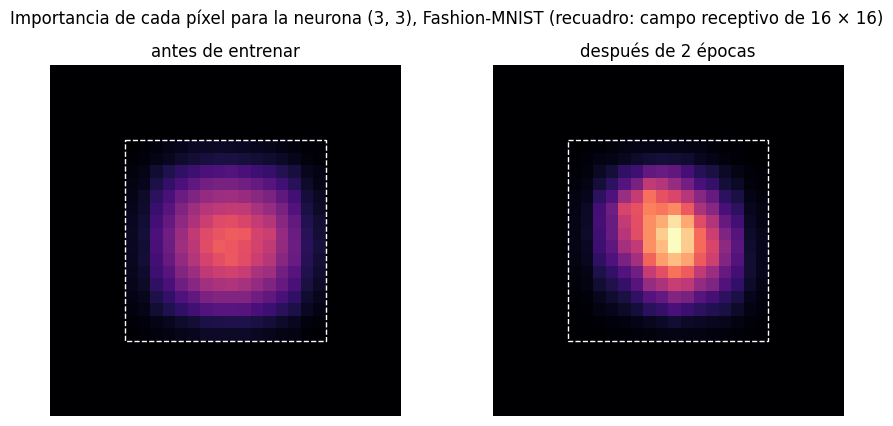

In [26]:
fig, ejes = plt.subplots(1, 2, figsize=(9, 4.3))
inicio_region, fin_region = region(capas_red, 3)
for eje, (titulo, mapa) in zip(ejes, [("antes de entrenar", antes), ("después de 2 épocas", despues)]):
    eje.imshow(mapa, cmap="magma", vmin=0, vmax=max(antes.max(), despues.max()))
    eje.add_patch(Rectangle((inicio_region - 0.5, inicio_region - 0.5), 16, 16, fill=False, edgecolor="white", linestyle="--"))
    eje.set_title(titulo)
    eje.axis("off")
plt.suptitle("Importancia de cada píxel para la neurona (3, 3), Fashion-MNIST (recuadro: campo receptivo de 16 × 16)")
plt.tight_layout()
plt.show()

Después de dos épocas, con 83.0% de exactitud de prueba, la importancia se **concentra** más en el centro: la desviación baja de 3.37 a 3.02 píxeles, la mitad de la importancia pasa de estar en 58 píxeles a estar en 43, y el 90%, de 155 a 124. Es lo contrario de lo que observaron Luo y otros.

No contradice su resultado, porque las condiciones son muy distintas. Ellos entrenaron hasta el final una ResNet de 17 bloques sin pooling, cuyo campo teórico, de 74 × 74, era más grande que la imagen; nosotros, dos épocas de una red de cuatro convoluciones con dos max pooling y un campo teórico de 16 × 16. Lo que el experimento sí muestra es que el campo receptivo efectivo no es una propiedad fija de la arquitectura: depende de los pesos, y el entrenamiento lo cambia. En esta red, la neurona central aprendió a apoyarse más en el centro de su región. El ejercicio 5 propone seguir entrenando para ver hacia dónde sigue.

## 13. Qué implica para diseñar una red

**Cuántas capas hacen falta para ver todo el objeto.** Con la fórmula del tamaño podemos contar cuántas convoluciones de 3 × 3 hacen falta para que una neurona vea una imagen completa, con tres diseños: solo convoluciones con paso 1; bloques como los de VGG, de dos convoluciones y un max pooling; y convoluciones con la dilatación duplicándose en cada capa (1, 2, 4, 8, ...).

In [27]:
def convoluciones_necesarias(siguiente_bloque, objetivo):
    capas, convoluciones = [], 0
    while campo(capas) < objetivo:
        bloque = siguiente_bloque(convoluciones)
        capas += bloque
        convoluciones += sum(c.nombre == "conv" for c in bloque)
    return convoluciones, campo(capas)


disenos = {
    "solo 3 × 3, paso 1": lambda n: [Capa("conv", 3, 1, 1)],
    "bloques conv-conv-pool": lambda n: [Capa("conv", 3, 1, 1), Capa("conv", 3, 1, 1), Capa("pool", 2, 2, 0)],
    "dilatación 1, 2, 4, ...": lambda n: [Capa("conv", 2 ** n * 2 + 1, 1, 2 ** n)],
}
print(f"{'diseño':24s}" + "".join(f"{'imagen de ' + str(t):>20s}" for t in [28, 32, 224]))
for nombre, siguiente in disenos.items():
    fila = f"{nombre:24s}"
    for objetivo in [28, 32, 224]:
        n, r = convoluciones_necesarias(siguiente, objetivo)
        fila += f"{f'{n} capas (r={r})':>20s}"
    print(fila)

diseño                          imagen de 28        imagen de 32       imagen de 224
solo 3 × 3, paso 1           14 capas (r=29)     16 capas (r=33)   112 capas (r=225)
bloques conv-conv-pool        6 capas (r=36)      6 capas (r=36)    12 capas (r=316)
dilatación 1, 2, 4, ...       4 capas (r=31)      5 capas (r=63)     7 capas (r=255)


Con solo convoluciones de paso 1, el campo receptivo crece 2 píxeles por capa: hacen falta 16 capas para cubrir 32 píxeles y 112 para cubrir 224. Con pooling, el crecimiento se vuelve multiplicativo: 6 convoluciones alcanzan para 28 o 32 píxeles y 12 para 224. (Con cinco bloques, 10 convoluciones, el campo llega a 156; VGG-16 reparte 13 convoluciones en cinco bloques y llega a 212, como vimos en la sección 9.) Con dilataciones que se duplican, el crecimiento es exponencial y sin perder resolución: 5 capas para 32 y 7 para 224. Es lo que dicen Luo y otros en su [sección 2.5](https://arxiv.org/abs/1701.04128): el submuestreo y las convoluciones dilatadas agrandan el campo receptivo de forma efectiva.

Hay que leer la tabla junto con la sección 11: el campo receptivo **efectivo** es más chico que el teórico, así que para que una neurona aproveche de verdad la imagen entera conviene que el teórico la supere con holgura.

**El campo receptivo no es todo.** El artículo encuentra una relación logarítmica entre la exactitud en ImageNet y el tamaño del campo receptivo, lo que sugiere que los campos receptivos grandes son necesarios para el reconocimiento de alto nivel, pero con retornos decrecientes. Y advierte que no es el único factor: la profundidad, el ancho, las conexiones residuales y la normalización por lotes también pesan; un campo receptivo grande sería necesario, pero "de ninguna manera suficiente" ([Distill, *Discussion: receptive fields of modern networks*](https://distill.pub/2019/computing-receptive-fields/)).

**La alineación de los centros.** Los centros de las regiones de neuronas vecinas están separados por el paso efectivo $S_0$. El artículo muestra que si todas las capas cumplen $p_l = (k_l - 1)/2$, los centros caen justo en los píxeles $0, S_0, 2S_0, \ldots$, lo que exige kernels impares ([Distill, *Computing receptive field region in input image*](https://distill.pub/2019/computing-receptive-fields/)). Un max pooling de 2 × 2 no puede cumplirlo. Comparamos `tres_bloques` con una variante que reemplaza cada pooling por una convolución de 3 × 3 con paso 2 y relleno 1:

In [28]:
con_paso = [Capa("conv", 3, 1, 1), Capa("conv", 3, 2, 1)] * 3
for nombre, capas in [("tres_bloques (pooling 2 × 2)", capas_de(tres_bloques)), ("convoluciones con paso 2", con_paso)]:
    centros = [centro(capas, u) for u in range(4)]
    print(f"{nombre:29s} r = {campo(capas):2d}   S0 = {paso_efectivo(capas)}   centros: {centros}")

tres_bloques (pooling 2 × 2)  r = 22   S0 = 8   centros: [3.5, 11.5, 19.5, 27.5]
convoluciones con paso 2      r = 29   S0 = 8   centros: [0.0, 8.0, 16.0, 24.0]


Con pooling de 2 × 2, los centros caen entre dos píxeles (3.5, 11.5, 19.5, 27.5), pero quedan simétricos respecto del centro de la imagen de 32 píxeles, 15.5. Con convoluciones de kernel impar y relleno $(k-1)/2$ en todas las capas, caen sobre píxeles (0, 8, 16, 24), como predice el artículo, pero ya no simétricos: el primero está en el borde y el último a 7 píxeles del otro borde. Para clasificar no importa mucho. Importa en las tareas en que cada salida corresponde a un lugar de la imagen, como la segmentación, que el artículo menciona entre las que necesitan características alineadas.

## 14. Resumen

- El **campo receptivo** de una neurona es la región de la imagen que puede influir en ella. Se ve directamente con el gradiente de esa neurona respecto de la entrada.
- Su tamaño sigue la recurrencia $r_{l-1} = s_l r_l + (k_l - s_l)$, que el artículo de Distill resuelve como $r_0 = \sum_l (k_l - 1)\prod_{i<l} s_i + 1$. Cada capa aporta $k_l - 1$ posiciones multiplicadas por los pasos anteriores. El relleno no cambia el tamaño.
- Tres capas de 3 × 3 ven lo mismo que una de 7 × 7, con $27C^2$ parámetros en vez de $49C^2$ y con no linealidades en medio.
- La **región** exacta sale del paso efectivo $S_0$ y el relleno efectivo $P_0$: empieza en $u_0 = -P_0 + u S_0$ y mide $r_0$. Lo comprobamos píxel a píxel en todas las neuronas de salida de tres redes, incluidas las del borde, cuya región entra en el relleno.
- Con ReLU y max pooling, una imagen concreta usa solo una parte de la región, pero nunca nada fuera de ella.
- Las neuronas convolucionales de las redes del módulo ven 10 × 10 (de 28 × 28) y 22 × 22 (de 32 × 32) píxeles; la capa lineal final es la que junta toda la imagen. VGG-16 reproduce la fila del artículo: 212, 32 y 90.
- La dilatación cambia $k$ por $\alpha(k-1) + 1$: más campo receptivo con los mismos parámetros. Una capa dilatada sola deja agujeros.
- El **campo receptivo efectivo** es gaussiano y mucho más chico que el teórico: su radio crece como $\sqrt{n}$ y no como $n$. Con 10 capas, la mitad de la importancia está en el 7% central.
- El campo receptivo efectivo depende de los pesos. En nuestra red de Fashion-MNIST, dos épocas de entrenamiento lo concentraron más en el centro, al revés de lo que Luo y otros observaron en una ResNet profunda entrenada hasta el final.

## Ejercicios

1. Antes de ejecutar nada: ¿cuál es el campo receptivo de una red con una convolución de 5 × 5 y paso 1, un max pooling de 3 × 3 con paso 3 y una convolución de 3 × 3? ¿Cuál es su paso efectivo? Compruébalo con `campo` y con `gradiente_de_una_neurona` sobre la versión lineal.
2. Agujeros: arma una red con dos capas de kernel 1 y paso 2. ¿Qué dice la fórmula del campo receptivo? Dibuja con `dibujar` los píxeles que usa una neurona de la salida. ¿Por qué la comprobación de la sección 7 fallaría con esta red?
3. Agrega un cuarto bloque a `tres_bloques` y calcula su tabla capa por capa sobre 32 × 32. ¿Qué tamaño tiene el mapa de salida? ¿Ve ahora cada neurona la imagen completa?
4. Repite la figura de la sección 11 con 20 capas y activaciones `nn.Tanh()` y `nn.Sigmoid()` en vez de ReLU (es la parte derecha de la figura 1 de Luo y otros). ¿Cuál se ve más gaussiana?
5. Entrena la red de la sección 12 durante más épocas, con las 60.000 imágenes, y mide la importancia al final de cada época. ¿Sigue cambiando el campo receptivo efectivo, y en qué dirección?
6. Calcula con `capas_de` el campo receptivo de `torchvision.models.resnet18(weights=None)`. Ojo: `modules()` recorre también las convoluciones de 1 × 1 de los atajos (`downsample`), que están en otro camino. ¿Por qué eso hace que la cuenta no sea correcta? Lee la sección *Arbitrary computation graphs* del artículo y explica qué habría que hacer.

## Fuentes

Las citas textuales que respaldan cada afirmación, con el lugar exacto donde están. Las páginas se revisaron el 22 de octubre de 2026.

**Del material del curso**

- **A. Araujo, W. Norris y J. Sim (2019)**, [*Computing Receptive Fields of Convolutional Neural Networks*](https://distill.pub/2019/computing-receptive-fields/), Distill, doi:10.23915/distill.00021.
  - Introducción: "The key parameter to associate an output feature to an input region is the receptive field of the convolutional network, which is defined as the size of the region in the input that produces the feature"; "if the receptive field of the network is small, it may not be able to recognize large objects"; "these computations are often done by hand, which is both tedious and error-prone".
  - *Problem setup*: "For higher-dimensional signals (e.g., 2D images), the derivations can be applied to each dimension independently"; "We define elementwise operations to have a “kernel size” of 1, since each output feature depends on a single location of the input feature maps"; "We adopt the convention where the first output feature for each layer is computed by placing the kernel on the left-most position of the input, including padding. This convention is adopted by all major deep learning libraries."
  - *Single-path networks*, *Computing receptive field size*: la recurrencia $r_{l-1} = s_l \cdot r_{l} + (k_l - s_l)$ y la solución $r_0 = \sum_{l=1}^{L} ((k_l-1)\prod_{i=1}^{l-1} s_i) + 1$; "This expression makes intuitive sense, which can be seen by considering some special cases. For example, if all kernels are of size 1, naturally the receptive field is also of size 1. If all strides are 1, then the receptive field will simply be the sum of $(k_l-1)$ over all layers, plus 1"; "If the stride is greater than 1 for a particular layer, the region increases proportionally for all layers below that one. Finally, note that padding does not need to be taken into account for this derivation"; "note that, in some cases, the receptive field region may contain “holes”, i.e., some of the input features may be unused for a given layer".
  - *Computing receptive field region in input image*: las fórmulas de $u_{l-1}$, $v_{l-1}$, $u_0$, $v_0$, el paso efectivo $S_l$, el relleno efectivo $P_l$ y sus recurrencias, y el centro $c_0$; el ejemplo "In this example, $u_2=v_2=0$, $u_1=0,v_1=1$, and $u_0=-1, v_0=4$"; "it is easy to show that $r_0 = v_0 - u_0 + 1$, which we leave as a follow-up exercise for the curious reader"; "the receptive field centers for the different output features are spaced by the effective stride $S_0$"; "if $p_l = \frac{k_l - 1}{2}$ for all $l$, the centers of the receptive field regions for the output features will be aligned to the first image pixel and located at ${0, S_0, 2S_0, 3S_0, \ldots}$ (note that in this case all $k_l$’s must be odd)".
  - *Arbitrary computation graphs*: "For many computer vision tasks, it is highly desirable that output features be aligned: “image-to-image translation” tasks (e.g., semantic segmentation, edge detection, surface normal estimation, colorization, etc)".
  - *Discussion: receptive fields of modern networks*: la tabla, con las filas "alexnet_v2 195 32 64" y "vgg_16 212 32 90", calculada sobre modelos que "are drawn from the TF-Slim image classification model library"; "We observe a logarithmic relationship between classification accuracy and receptive field size, which suggests that large receptive fields are necessary for high-level recognition tasks, but with diminishing rewards"; "while we conjecture that a large receptive field is necessary, by no means it is sufficient"; "the input pixels near the center of the receptive field have more “paths” to influence the feature, and consequently carry more weight. The relative importance of each input pixel defines the effective receptive field of the feature"; "experimentally observing a Gaussian shape, with the peak at the receptive field center".
  - Apéndice *Other network operations*: "Dilating a kernel by a factor of $\alpha$ introduces striding of $\alpha$ between the samples used when computing the convolution. This means that the spatial span of the kernel ($k>0$) is increased to $\alpha (k-1) + 1$. The above derivations can be reused by simply replacing the kernel size $k$ by $\alpha (k-1) + 1$ for all layers using dilations."
- **CS231n**, [*Convolutional Neural Networks: Architectures, Convolution / Pooling Layers*](https://cs231n.github.io/convolutional-networks/):
  - *Convolutional Layer*, *Local Connectivity*: "The spatial extent of this connectivity is a hyperparameter called the receptive field of the neuron (equivalently this is the filter size)."
  - *Convolutional Layer*, *Dilated convolutions*: "it allows you to merge spatial information across the inputs much more agressively with fewer layers. For example, if you stack two 3x3 CONV layers on top of each other then you can convince yourself that the neurons on the 2nd layer are a function of a 5x5 patch of the input".
  - *ConvNet Architectures*, *Layer Patterns*: "Prefer a stack of small filter CONV to one large receptive field CONV layer"; "a neuron on the third CONV layer has a 3x3 view of the 2nd CONV layer, and hence a 7x7 view of the input volume"; "the neurons would be computing a linear function over the input, while the three stacks of CONV layers contain non-linearities that make their features more expressive"; "the single 7x7 CONV layer would contain $C \times (7 \times 7 \times C) = 49 C^2$ parameters, while the three 3x3 CONV layers would only contain $3 \times (C \times (3 \times 3 \times C)) = 27 C^2$ parameters"; "we might need more memory to hold all the intermediate CONV layer results if we plan to do backpropagation".

**Artículo citado por Distill (no está en la lista del curso)**

- **W. Luo, Y. Li, R. Urtasun y R. Zemel (2016)**, [*Understanding the Effective Receptive Field in Deep Convolutional Neural Networks*](https://arxiv.org/abs/1701.04128), NIPS 2016. Es la referencia 17 de Distill para el campo receptivo efectivo.
  - Resumen: "We introduce the notion of an effective receptive field, and show that it both has a Gaussian distribution and only occupies a fraction of the full theoretical receptive field."
  - Sección 1: "the currently commonly used random initializations lead some deep CNNs to start with a small effective receptive field, which then grows during training."
  - Sección 2: "The measure of impact we use in this paper is the partial derivative $\partial y_{0,0}/\partial x^0_{i,j}$"; "we can set the error gradient $\partial l/\partial y_{0,0} = 1$ and $\partial l/\partial y_{i,j} = 0$ for all $i \neq 0$ and $j \neq 0$, then propagate this gradient from there back down the network".
  - Sección 2.3: "If we take one standard deviation as the effective receptive field (ERF) size which is roughly the radius of the ERF, then this size is $\sqrt{Var[S_n]} = \sqrt{nVar[X_i]} = O(\sqrt{n})$"; "relative to the theoretical receptive field, the ERF actually shrinks at a rate of $O(1/\sqrt{n})$"; y la ecuación 11, $\sqrt{Var[S_n]} = \sqrt{n(k^2-1)/12} = O(k\sqrt{n})$ para pesos uniformes.
  - Sección 2.5: "Subsampling and dilated convolutions turn out to be effective ways to increase receptive field size quickly."
  - Sección 3.1: "we can observe perfect Gaussian shapes for uniformly and randomly weighted convolution kernels without nonlinear activations, and near Gaussian shapes for randomly weighted kernels with nonlinearity"; "ReLU units output exactly zero for half of its inputs and it is very easy to get a zero output for the center pixel on the output plane, which means no path from the receptive field can reach the output, hence the gradient is all zero"; "Here the ERFs are averaged over 20 runs with different random seed"; "The best fitting line for ERF size gives slope of 0.56 in log domain, while the line for ERF ratio gives slope of -0.43"; "we use 2 standard deviations as our measurement for ERF size, i.e. any pixel with value greater than 1 − 95.45% of center point is considered as in ERF".
  - Sección 3.2: "Intriguingly, as the networks learns, the ERF gets bigger, and at the end of training is significantly larger than the initial ERF", con "a ResNet with 17 residual blocks on the CIFAR-10 dataset", "we did not use pooling or downsampling" y "the theoretical receptive field of our network is actually 74 × 74, bigger than the image size".

**Lo que no viene de una fuente** son los números de este notebook (las comprobaciones con redes al azar y con gradientes, las tablas capa por capa, los parámetros, las medidas del campo receptivo efectivo y el entrenamiento): todos salen de las celdas de código. También son nuestros la versión lineal con pesos 1 para comprobar las regiones, la comparación de la sección 8 con ReLU y max pooling, la cuenta de capas de la sección 13 y la comparación de los centros con pooling y con convoluciones con paso.